# Pandas cheat sheet: merge and missing values

## 1. Merge two DataFrames

| Goal | Code |
|---|---|
| Check the sizes | `df_main.shape`, `df_opinion.shape`, `len(df_main)` |
| Merge, same column name | `pd.merge(df_main, df_opinion, on="DATE")` |
| Merge, different names | `pd.merge(df_main, df_opinion, left_on="DATE", right_on="date")` |
| Choose the merge type | `pd.merge(..., how="left")` |
| Rename a column first | `df_opinion = df_opinion.rename(columns={"date": "DATE"})` |
| Drop a column | `df2018 = df2018.drop(columns="date")` |
| Drop in place | `df2018.drop("date", axis=1, inplace=True)` |

| `how=` | What it keeps |
|---|---|
| `"inner"` (default) | Only the dates found in both files |
| `"left"` | **All dates of the first (left) file**, `NaN` where the other file has nothing |
| `"right"` | All dates of the second (right) file |
| `"outer"` | All dates of both files |

Think about the question in the exercise: which file must keep all its 365 dates?

Column count after the merge:

| Method | Result |
|---|---|
| `on=` (same name) | 1 date column, so 20 columns |
| `left_on=` and `right_on=` | 2 date columns, so 21 columns, then drop `date` |

## 2. Find missing values

| Goal | Code |
|---|---|
| Info per column (non-null count) | `df2018.info()` |
| `True` where missing | `df2018.isna()` |
| Number of missing per column | `df2018.isna().sum()` |
| Rows with a missing value in one column | `df2018[df2018["OPINION"].isna()]` |
| Only the dates of those rows | `df2018[df2018["OPINION"].isna()]["DATE"]` |
| The opposite (not missing) | `.notna()` |
| Count values | `df2018["flag"].value_counts()` |

`isna()` on the whole DataFrame also works. To get the 24 dates, think about which column the missing rows come from (the ones that had no match in the opinion file).

## 3. The flag column

| Goal | Code |
|---|---|
| Create a True/False column | `df2018["flag"] = df2018["OPINION"].isna()` |

Create it **before** filling the NaN. After filling, you could not find those rows anymore.

## 4. Quick plots with pandas

| Goal | Code |
|---|---|
| Scatter plot | `df2018.plot.scatter(x="DATE", y="SUNHOUR")` |
| Boxplot | `df2018["col"].plot.box()` |
| Boxplot (other way) | `df2018.boxplot(column="col")` |
| Line plot | `df2018["col"].plot()` |
| Histogram | `df2018["col"].plot.hist()` |

If the date axis looks strange, convert it first: `df2018["DATE"] = pd.to_datetime(df2018["DATE"])`.

## 5. Statistics

| Goal | Code |
|---|---|
| Mean, median | `df2018["col"].mean()`, `df2018["col"].median()` |
| Most frequent value | `df2018["col"].mode()[0]` |
| Min, max | `df2018["col"].min()`, `.max()` |
| A quantile (0.1 = first decile) | `df2018["col"].quantile(0.1)` |
| Summary | `df2018["col"].describe()` |

For the 9 deciles plus min and max, use a loop. `quantile(0)` is the min and `quantile(1)` is the max. Example of values to loop on: `[0, 0.1, 0.2, ..., 1]`. You can build them with `range` and a division by 10.

## 6. Fill missing values

| Goal | Code |
|---|---|
| Fill with a value | `df2018["col"] = df2018["col"].fillna(value)` |
| Fill with the mean | `df2018["col"] = df2018["col"].fillna(df2018["col"].mean())` |
| Fill with a text | `df2018["OPINION"] = df2018["OPINION"].fillna("unknown")` |
| Propagate the previous value | `df2018["col"] = df2018["col"].ffill()` |
| Propagate the next value | `df2018["col"] = df2018["col"].bfill()` |
| Check what is left | `df2018["col"].isna().sum()` |

**Important notes:**

- The exercise uses `fillna(..., inplace=True)` on a column. In recent pandas this may do **nothing** or give a warning. The safe way is to assign the result back: `df2018["col"] = df2018["col"].fillna(...)`.
- The exercise also uses `fillna(method="ffill")`. In recent pandas this is replaced by `.ffill()` and `.bfill()`.
- Which method for which column: a code or a count (`WEATHER_CODE_EVENING`, `TOTAL_SNOW_MM`, `UV_INDEX`) often uses a typical value (mean, median or mode). A value that changes day by day (`SUNHOUR`) is better with propagation. Text (`OPINION`) gets a label.

## 7. Plot the changes with seaborn

| Goal | Code |
|---|---|
| Import | `import seaborn as sns`, `import matplotlib.pyplot as plt` |
| Colour by the flag | `sns.scatterplot(data=df2018, x="DATE", y="col", hue="flag")` |
| Choose the colours | add `palette={False: "blue", True: "red"}` |
| 4 plots in one figure | `fig, axes = plt.subplots(2, 2, figsize=(12, 8))` |
| Draw in one box | `sns.scatterplot(..., ax=axes[0, 0])` |
| Flatten the boxes to loop | `for ax, col in zip(axes.flatten(), columns):` |
| Clean layout | `plt.tight_layout()` |
| Show | `plt.show()` |

## 8. Common mistakes

| Error | Cause | Fix |
|---|---|---|
| `NameError: df2018 is not defined` | The merge cell was not run | Run the cells in order |
| 20 or 21 columns, not what you expect | `on` versus `left_on` and `right_on` | See the table in part 1 |
| Fewer than 365 rows | `inner` merge | Use the right `how=` |
| NaN still there after `fillna` | Result not kept | Assign it back to the column |
| Flag is all `False` | Created after the filling | Create it before |
| Warning about `inplace` on a column | Chained assignment | Use `df["col"] = df["col"].fillna(...)` |

## Order of work

1. Check sizes, then merge.
2. Drop the extra date column if needed.
3. Find the missing dates.
4. Create the flag.
5. Look at each column, then choose a filling method.
6. Fill, then check with `info()`.
7. Plot with `hue="flag"`.

# Execute the code below

In [127]:
import pandas as pd
import numpy as np
link = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather2019.csv"
df_weather = pd.read_csv(link)

## You have now a DataFrame with lots of weather data

In [128]:
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,WINDTEMP_MAX_C,WEATHER_CODE_MORNING,WEATHER_CODE_NOON,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,MONTH,DAY
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.0,...,3,116,143,176,0,1,5.1,very bad,1,1
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.0,...,3,119,116,116,0,1,8.7,very bad,1,2
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.0,...,-4,116,116,116,0,1,8.7,very bad,1,3
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.0,...,-4,116,116,122,0,1,5.1,very bad,1,4
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.0,...,-2,143,116,116,0,1,8.7,very bad,1,5


# Now, complete the following tasks :
# Let's go in the deep !

## 1 - Merge
OK, you know very well the previous dataset. Now, you want more, much more. Another year for example ?

But it's too bad. The year 2018 is not in the good  shape. There are 2 files :
- The main file with Temperature, etc...
- The opinion file, with especially the Opinion

The goal is [to merge](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.merge.html) both files in one DataFrame called **df2018**. It seems both files have a date column with the same format (but not the same name).

Think about checking if both datasets have the same length. If they don't, what kind of merge do you have to do to keep each date of the main dataset ? Then apply this specific merge.

In [129]:
link_main = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather_main_2018.csv"
link_opinion = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather_opinion_2018.csv"
df_main = pd.read_csv(link_main)
df_opinion = pd.read_csv(link_opinion)

In [130]:
df_main.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,PRESSURE_MAX_MB,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,1018,41.750,12,8,7
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,1020,87.875,13,12,6
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,1017,91.500,15,13,7
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,1011,90.125,14,12,10
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,1005,62.375,12,10,7


In [131]:
df_opinion.head()

,date,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION
0,2018-01-01,113,0,3,5.1,bad
1,2018-03-12,119,0,2,8.8,bad
2,2018-03-09,116,0,3,10.2,bad
3,2018-10-07,122,0,1,5.6,bad
4,2018-06-18,119,0,1,12.9,bad


In [132]:
# Your code here :
df2018 = pd.merge(df_main, df_opinion, left_on="DATE", right_on="date", how="left")
df2018

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C,date,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,...,41.750,12,8,7,2018-01-01,113.0,0.0,3.0,5.1,bad
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,...,87.875,13,12,6,2018-01-02,122.0,0.0,3.0,3.3,bad
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,...,91.500,15,13,7,2018-01-03,122.0,0.0,3.0,3.3,bad
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,...,90.125,14,12,10,2018-01-04,116.0,0.0,3.0,3.3,bad
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,...,62.375,12,10,7,2018-01-05,116.0,0.0,3.0,6.9,bad
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2018-12-27,7,2,6,2,6,5,0.0,85,10.000,...,30.750,8,6,3,2018-12-27,119.0,0.0,1.0,8.7,very bad
361,2018-12-28,7,2,8,2,7,3,0.0,89,8.000,...,18.750,8,4,4,2018-12-28,113.0,0.0,1.0,8.7,very bad
362,2018-12-29,7,1,6,1,6,4,0.0,94,7.000,...,33.000,8,5,1,2018-12-29,116.0,0.0,1.0,8.7,very bad
363,2018-12-30,9,4,6,5,9,8,0.1,95,6.000,...,70.375,10,9,7,2018-12-30,143.0,0.0,1.0,3.3,very bad


### Result

Your DataFrame **df2018** should now have 21 columns and 365 rows. If not, try again.

**Be careful:**
- if you've renamed your `date` column, then merged both DataFrames with `on` parameter, Pandas kept only one `DATE` column. So you'll have 20 columns in your DataFrame. And you can skip the "drop" step just after.
- if you merged with `left_on` and `right_on` parameters, Pandas kept both columns `DATE` and `date`, and you'll have 21 columns in your DataFrame. You can do this "drop" step:



In [133]:
# You should now probably drop the "date" column.
# This column is incomplete, it were provided from the opinion file.
# It was very useful to perform the "merge". But we don't need it anymore.

# Read and execute the code below :
df2018.drop('date',             # Select column to drop
            axis = 1,           # Precise if you want to drop a column (1) or a row (0)
            inplace = True)     # If we don't use this argument, result is not stored

Now, everybody should have a 20 columns and 365 rows.

**Ohhhh, there are some missing values, we have to fill them. That will be the goal of this quest: to learn how to fill in the missing values, column by column, with different techniques.**

In [134]:
# Just execute the code below, to display a "non-null" column :
print("My DataFrame shape is : ", df2018.shape, end = '\n\n\n\n')
print('Which columns have missing values ? (Non-null column)')
print(df2018.info())


My DataFrame shape is :  (365, 20)



Which columns have missing values ? (Non-null column)
<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    365 non-null    str    
 1   MAX_TEMPERATURE_C       365 non-null    int64  
 2   MIN_TEMPERATURE_C       365 non-null    int64  
 3   WINDSPEED_MAX_KMH       365 non-null    int64  
 4   TEMPERATURE_MORNING_C   365 non-null    int64  
 5   TEMPERATURE_NOON_C      365 non-null    int64  
 6   TEMPERATURE_EVENING_C   365 non-null    int64  
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64  
 9   VISIBILITY_AVG_KM       365 non-null    float64
 10  PRESSURE_MAX_MB         365 non-null    int64  
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64
 12  HEATINDEX_MAX_C         365 non-null    int64  
 13  DEWPOINT_MAX_C

### Find and display the Dates of missing values.
You can help you with the method `.isna()`

You have to find 24 different dates.

In [135]:
# Your code here :

missing_rows = df2018.isna().any(axis=1)
df2018["DATE"][missing_rows]

18     2018-01-19
31     2018-02-01
66     2018-03-08
100    2018-04-11
118    2018-04-29
143    2018-05-24
152    2018-06-02
163    2018-06-13
165    2018-06-15
175    2018-06-25
184    2018-07-04
191    2018-07-11
194    2018-07-14
197    2018-07-17
204    2018-07-24
220    2018-08-09
225    2018-08-14
234    2018-08-23
266    2018-09-24
317    2018-11-14
321    2018-11-18
325    2018-11-22
346    2018-12-13
349    2018-12-16
Name: DATE, dtype: str

## 2 - Before filling missing values, you have to create a new axis "flag", to document and to remember which lines you modify.

In [136]:
# Just execute the code below :
df2018['flag'] = df2018['OPINION'].isna()
df2018['flag'].value_counts()

flag
False    341
True      24
Name: count, dtype: int64

## 3 - Visualize and Fill the NaN

### 3.1 - First column : WEATHER_CODE_EVENING

You have to visualize how are the well-filled data. Of course you know Matplotlib, and maybe, you know Seaborn and Plotly. But, did you know that Pandas integrate directly some parts of Matplotlib ? It's very useful, and don't need to import other libraries...

#### Scatterplot directly with Pandas

<Axes: xlabel='DATE', ylabel='WEATHER_CODE_EVENING'>

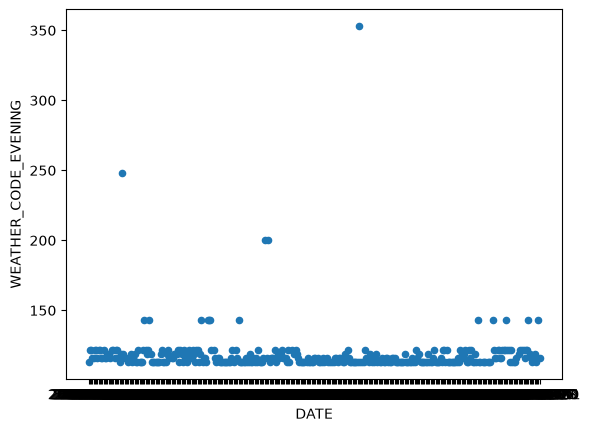

In [137]:
# Draw a scatterplot with Date on X-axis and WEATHER_CODE_EVENING on Y-axis
df2018.plot.scatter(x="DATE", y="WEATHER_CODE_EVENING") #Code to complete

#### Boxplot directly with Pandas

Here you can find [a little help](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.boxplot.html)

<Axes: >

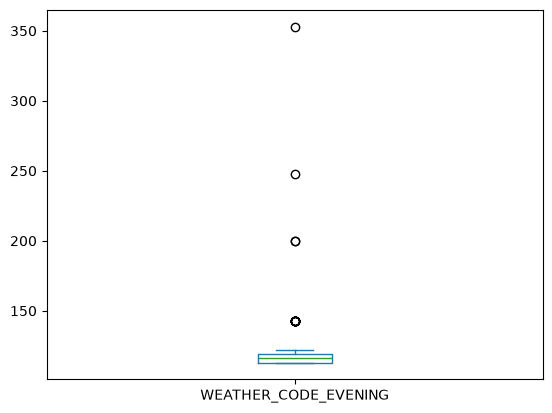

In [138]:
# Find a way to draw directly with pandas a boxplot on the column WEATHER_CODE_EVENING

df2018["WEATHER_CODE_EVENING"].plot.box()

<Axes: >

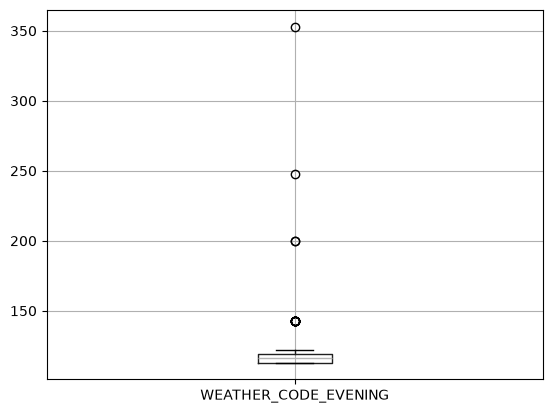

In [139]:
df2018.boxplot(column="WEATHER_CODE_EVENING")

#### Deciles

Here you can find [a little help](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html)

In [140]:
# Find a way to print the 9 deciles + min + max of the column WEATHER_CODE_EVENING with the quantile method of pandas and a loop

for x in range(0, 11):
    print(df2018["WEATHER_CODE_EVENING"].quantile(x/10))

113.0
113.0
113.0
113.0
113.0
116.0
116.0
119.0
122.0
122.0
353.0


#### Fill values
OK it seems that the most of datas are between 113 and 122. Maybe, we could fill the missing values with Mean or Median, it's up to you to choose. So you need :
- Calculate the mean or the median
- Fill the missing values only for **WEATHER_CODE_EVENING** with the `fillna()` method

When you're OK, remember tu use the `inplace=True` argument, otherwise, your modification will not be stored.

In [142]:
mean_weather_column = df2018["WEATHER_CODE_EVENING"].median()
mean_weather_column

np.float64(116.0)

In [143]:
df2018.fillna({'WEATHER_CODE_EVENING': mean_weather_column}, inplace=True) # When you are OK, you can replace this argument by True

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,flag
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,...,41.750,12,8,7,113.0,0.0,3.0,5.1,bad,False
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,...,87.875,13,12,6,122.0,0.0,3.0,3.3,bad,False
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,...,91.500,15,13,7,122.0,0.0,3.0,3.3,bad,False
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,...,90.125,14,12,10,116.0,0.0,3.0,3.3,bad,False
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,...,62.375,12,10,7,116.0,0.0,3.0,6.9,bad,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2018-12-27,7,2,6,2,6,5,0.0,85,10.000,...,30.750,8,6,3,119.0,0.0,1.0,8.7,very bad,False
361,2018-12-28,7,2,8,2,7,3,0.0,89,8.000,...,18.750,8,4,4,113.0,0.0,1.0,8.7,very bad,False
362,2018-12-29,7,1,6,1,6,4,0.0,94,7.000,...,33.000,8,5,1,116.0,0.0,1.0,8.7,very bad,False
363,2018-12-30,9,4,6,5,9,8,0.1,95,6.000,...,70.375,10,9,7,143.0,0.0,1.0,3.3,very bad,False


In [144]:
df2018['WEATHER_CODE_EVENING'].value_counts()

WEATHER_CODE_EVENING
113.0    154
116.0    102
122.0     59
119.0     34
143.0     12
200.0      2
248.0      1
353.0      1
Name: count, dtype: int64

In [145]:
df2018["WEATHER_CODE_EVENING"].isna().sum()

np.int64(0)

In [148]:
# You can use this code to check how many missing values you have :
column_name = 'WEATHER_CODE_EVENING'
print("I have",df2018[column_name].isna().sum(), "missing values in the column", column_name)

I have 0 missing values in the column WEATHER_CODE_EVENING


### 3.2 - Next columns : TOTAL_SNOW_MM and UV_INDEX

We trust you to choose right values to fill for both columns

In [149]:
# Your code here
df2018["TOTAL_SNOW_MM"] = df2018["TOTAL_SNOW_MM"].mode()[0]
df2018["UV_INDEX"] = df2018["UV_INDEX"].bfill()


In [150]:
df2018.isna().sum()

DATE                       0
MAX_TEMPERATURE_C          0
MIN_TEMPERATURE_C          0
WINDSPEED_MAX_KMH          0
TEMPERATURE_MORNING_C      0
TEMPERATURE_NOON_C         0
TEMPERATURE_EVENING_C      0
PRECIP_TOTAL_DAY_MM        0
HUMIDITY_MAX_PERCENT       0
VISIBILITY_AVG_KM          0
PRESSURE_MAX_MB            0
CLOUDCOVER_AVG_PERCENT     0
HEATINDEX_MAX_C            0
DEWPOINT_MAX_C             0
WINDTEMP_MAX_C             0
WEATHER_CODE_EVENING       0
TOTAL_SNOW_MM              0
UV_INDEX                   0
SUNHOUR                   24
OPINION                   24
flag                       0
dtype: int64

### 3.3 - Next column :
SUNHOUR

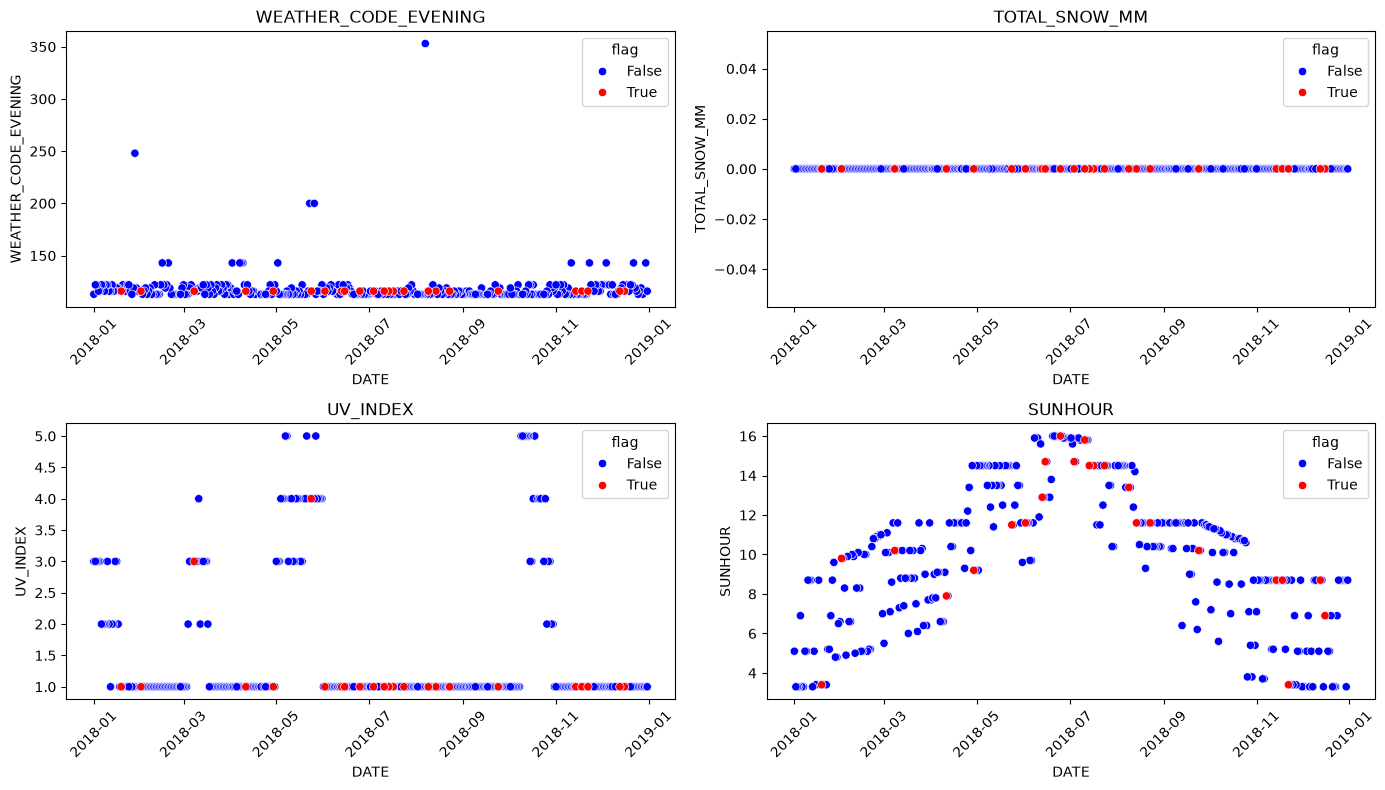

In [167]:
# Draw a scatterplot with Date on X-axis and SUNHOUR on Y-axis
import seaborn as sns
import matplotlib.pyplot as plt


sns.scatterplot(data=df2018, x="DATE", y="SUNHOUR", hue="flag")




#### Propagation
**It seems this is not a good idea to apply the same value all year long...**

You could use the the `method = 'ffill'` or `'bfill'` argument in `fillna()` to propagate non-null values forward or backward.

In [154]:
df2018["SUNHOUR"] = df2018["SUNHOUR"].bfill()

### 3.4 - Column : OPINION
For Opinion, we have not yet idea. So, we can write a new value 'unknown' in this column.

In [155]:
# Your code here
df2018["OPINION"] = df2018["OPINION"].fillna("unknown")


## Now, each axis should have 365 non-null values.

In [156]:
df2018.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    365 non-null    str    
 1   MAX_TEMPERATURE_C       365 non-null    int64  
 2   MIN_TEMPERATURE_C       365 non-null    int64  
 3   WINDSPEED_MAX_KMH       365 non-null    int64  
 4   TEMPERATURE_MORNING_C   365 non-null    int64  
 5   TEMPERATURE_NOON_C      365 non-null    int64  
 6   TEMPERATURE_EVENING_C   365 non-null    int64  
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64  
 9   VISIBILITY_AVG_KM       365 non-null    float64
 10  PRESSURE_MAX_MB         365 non-null    int64  
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64
 12  HEATINDEX_MAX_C         365 non-null    int64  
 13  DEWPOINT_MAX_C          365 non-null    int64  
 14  WINDTEMP_MAX_C          365 non-null    int64  
 15  

## 4 - Visualize your modifications
Draw 4 scatterplots with Date on X-axis, and each of the 4 numeric modified columns on Y-axis :
- The original datas will be in blue
- The new data (your datas) in red

It's the moment to use your "flag" column created at the beginning. It'll be easier in seaborn with `hue` argument.

You should get something like this:

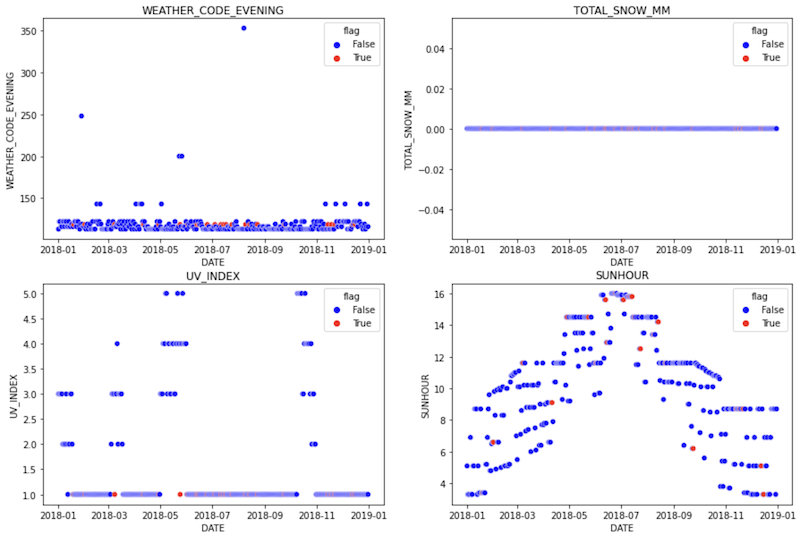

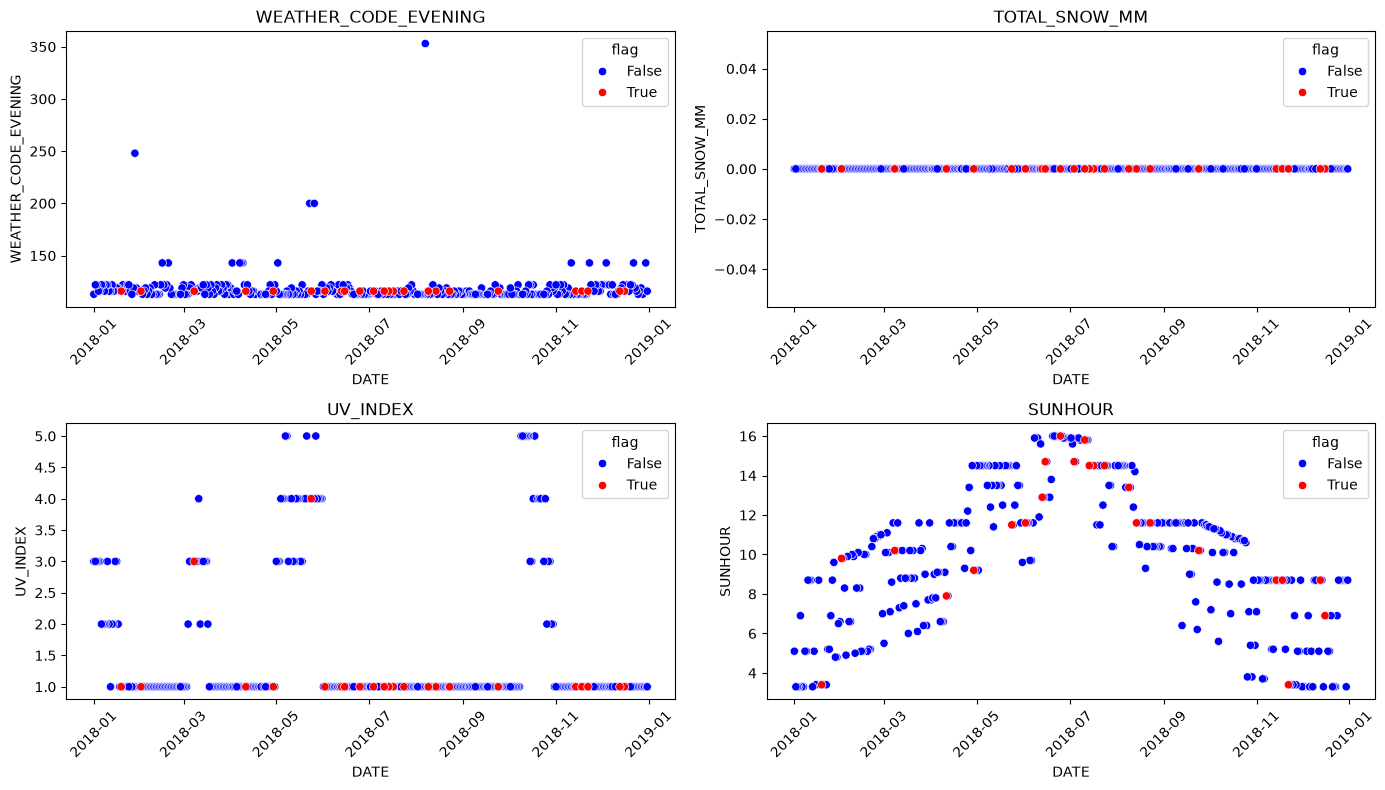

In [168]:
df2018["DATE"] = pd.to_datetime(df2018["DATE"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
columns = ["WEATHER_CODE_EVENING", "TOTAL_SNOW_MM", "UV_INDEX", "SUNHOUR"]
data_sorted = df2018.sort_values("flag")

for ax, column in zip(axes.flatten(), columns):
    sns.scatterplot(
        data=data_sorted,
        x="DATE",
        y=column,
        hue="flag",
        palette={False: "blue", True: "red"},
        ax=ax,
    )
    ax.set_title(column)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()